# ANN para clasificar el Wine Dataset

**Juan David Sierra Orozco**
Inteligencia Artificial (SI3003), EAFIT

## Enunciado

Entrenar una ANN para clasificar los elementos del dataset Wine. Hacer validación cruzada, partición 70/30. Usar activación sigmoide y función de costo de error (MSE). Mostrar frontera de decisión y resultados.

## Continuidad con los ejercicios anteriores

Esta red es literalmente la continuación de los dos ejercicios de la neurona única: **backpropagation es exactamente el mismo procedimiento, aplicado dos veces en cadena.** La neurona de salida se ajusta igual que antes; la capa oculta se ajusta usando la regla de la cadena para repartir "la culpa" del error hacia atrás.

$$
\hat{y} = \sigma\Big(W_2\,\sigma(W_1 x + b_1) + b_2\Big), \qquad
\text{costo} = \text{MSE}(y, \hat{y}) = \frac{1}{n}\sum (y-\hat{y})^2
$$

Y la lección del Ejercicio 2 vuelve a aparecer, palabra por palabra: **Wine tiene variables en escalas radicalmente distintas** (`proline` va de 278 a 1680, mientras `hue` va de 0.48 a 1.71). Sin normalizar antes de entrar a una sigmoide, la neurona satura exactamente como en el ejercicio anterior. Se verifica esto con números antes de entrenar el modelo final, no se da por sentado.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

np.random.seed(42)

---

## 1. Cargar y explorar los datos

178 vinos, 13 variables físico-químicas, 3 cultivares (clases).

In [2]:
datos = load_wine()
X, y = datos.data, datos.target
NOMBRES_VAR = datos.feature_names
NOMBRES_CLASE = datos.target_names
N_CLASES = 3

print(f"Muestras: {X.shape[0]}   variables: {X.shape[1]}")
print(f"Clases: {list(NOMBRES_CLASE)}   distribución: {np.bincount(y)}")

print()
print(f"{'variable':<25} | {'min':>9} | {'max':>9}")
print("-" * 50)
for i, nombre in enumerate(NOMBRES_VAR):
    print(f"{nombre:<25} | {X[:,i].min():>9.2f} | {X[:,i].max():>9.2f}")

Muestras: 178   variables: 13
Clases: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]   distribución: [59 71 48]

variable                  |       min |       max
--------------------------------------------------
alcohol                   |     11.03 |     14.83
malic_acid                |      0.74 |      5.80
ash                       |      1.36 |      3.23
alcalinity_of_ash         |     10.60 |     30.00
magnesium                 |     70.00 |    162.00
total_phenols             |      0.98 |      3.88
flavanoids                |      0.34 |      5.08
nonflavanoid_phenols      |      0.13 |      0.66
proanthocyanins           |      0.41 |      3.58
color_intensity           |      1.28 |     13.00
hue                       |      0.48 |      1.71
od280/od315_of_diluted_wines |      1.27 |      4.00
proline                   |    278.00 |   1680.00


`proline` llega a 1680; `nonflavanoid_phenols` no pasa de 0.66. Esa diferencia de más de tres órdenes de magnitud es lo que va a saturar la sigmoide si no se corrige.

---

## 2. La arquitectura: una ANN de una capa oculta

$$
a_1=\sigma(XW_1+b_1),\qquad \hat{y}=a_2=\sigma(a_1W_2+b_2)
$$

Las etiquetas se codifican **one-hot**: la clase 1 es $(1,0,0)$, la clase 2 es $(0,1,0)$, la clase 3 es $(0,0,1)$, para que la salida tenga 3 neuronas (una por clase) y se pueda usar MSE directamente contra ese vector.

In [3]:
def sigmoide(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))


def dsigmoide(salida):
    """Derivada de la sigmoide, en funcion de su propia salida: s(1-s)."""
    return salida * (1 - salida)


class ANN:
    """Red de una capa oculta: entrada -> sigmoide -> sigmoide -> salida."""

    def __init__(self, n_entrada, n_oculta, n_salida, seed=0):
        rng = np.random.RandomState(seed)
        self.W1 = rng.normal(0, 0.5, (n_entrada, n_oculta))
        self.b1 = np.zeros(n_oculta)
        self.W2 = rng.normal(0, 0.5, (n_oculta, n_salida))
        self.b2 = np.zeros(n_salida)

    def forward(self, X):
        self.a1 = sigmoide(X @ self.W1 + self.b1)
        self.a2 = sigmoide(self.a1 @ self.W2 + self.b2)
        return self.a2

    def costo(self, X, Y):
        """Funcion de costo: error cuadratico medio."""
        pred = self.forward(X)
        return np.mean((Y - pred) ** 2)

    def backward(self, X, Y, lr):
        m = X.shape[0]

        # Capa de salida: igual que en la neurona unica del Ejercicio 2.
        error_salida = self.a2 - Y
        delta2 = error_salida * dsigmoide(self.a2)

        # Capa oculta: la regla de la cadena reparte el error hacia atras,
        # ponderado por los pesos W2 que conectan cada neurona oculta
        # con las neuronas de salida a las que contribuyo.
        delta1 = (delta2 @ self.W2.T) * dsigmoide(self.a1)

        self.W2 -= lr * (self.a1.T @ delta2) / m
        self.b2 -= lr * delta2.mean(axis=0)
        self.W1 -= lr * (X.T @ delta1) / m
        self.b1 -= lr * delta1.mean(axis=0)

    def entrenar(self, X, Y, epochs, lr):
        historia = []
        for _ in range(epochs):
            self.forward(X)
            self.backward(X, Y, lr)
            historia.append(self.costo(X, Y))
        return historia

    def predecir(self, X):
        return np.argmax(self.forward(X), axis=1)


print("Clase ANN definida: entrada -> sigmoide (oculta) -> sigmoide (salida), costo MSE.")

Clase ANN definida: entrada -> sigmoide (oculta) -> sigmoide (salida), costo MSE.


---

## 3. Verificar la saturación antes de entrenar el modelo final

Partición 70/30, y se entrena **sin escalar**, dejando que `proline` entre tal cual, en cientos.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42)
Y_train = np.eye(N_CLASES)[y_train]

red_sin_escalar = ANN(13, 8, 3, seed=1)
hist_sin = red_sin_escalar.entrenar(X_train, Y_train, epochs=2000, lr=0.5)
acc_sin = np.mean(red_sin_escalar.predecir(X_test) == y_test)
saturacion_sin = np.mean((red_sin_escalar.a1 > 0.99) | (red_sin_escalar.a1 < 0.01))

print(f"MSE inicial : {hist_sin[0]:.4f}")
print(f"MSE final   : {hist_sin[-1]:.4f}")
print(f"Exactitud en prueba : {acc_sin:.1%}")
print(f"Neuronas de la capa oculta saturadas: {saturacion_sin:.0%}")

MSE inicial : 0.3388
MSE final   : 0.2191
Exactitud en prueba : 38.9%
Neuronas de la capa oculta saturadas: 100%


**Se confirma la misma falla del Ejercicio 2.** El 100% de las activaciones de la capa oculta quedan saturadas en 0 o en 1, y la exactitud (38.9%) apenas supera adivinar al azar entre 3 clases (33%). Sin normalizar, la red no tiene forma de aprender: la sigmoide muere contra sus propios extremos antes de que el gradiente pueda decir nada útil.

---

## 4. Estandarizar las variables y entrenar el modelo real

Se centra cada variable en su media y se divide por su desviación estándar, calculadas **solo con el conjunto de entrenamiento**, para no filtrar información del conjunto de prueba.

In [5]:
media_train = X_train.mean(axis=0)
sigma_train = X_train.std(axis=0)

X_train_s = (X_train - media_train) / sigma_train
X_test_s = (X_test - media_train) / sigma_train

N_OCULTA = 8
LR = 0.5
EPOCHS = 2000

red = ANN(13, N_OCULTA, N_CLASES, seed=1)
historia_costo = red.entrenar(X_train_s, Y_train, epochs=EPOCHS, lr=LR)

acc_train = np.mean(red.predecir(X_train_s) == y_train)
acc_test = np.mean(red.predecir(X_test_s) == y_test)
saturacion_con = np.mean((red.a1 > 0.99) | (red.a1 < 0.01))

print(f"MSE inicial : {historia_costo[0]:.4f}")
print(f"MSE final   : {historia_costo[-1]:.4f}")
print(f"Exactitud en entrenamiento : {acc_train:.1%}")
print(f"Exactitud en prueba        : {acc_test:.1%}")
print(f"Neuronas de la capa oculta saturadas: {saturacion_con:.0%}  (algo de saturación es normal en un modelo ya entrenado)")

MSE inicial : 0.2727
MSE final   : 0.0020
Exactitud en entrenamiento : 100.0%
Exactitud en prueba        : 98.1%
Neuronas de la capa oculta saturadas: 20%  (algo de saturación es normal en un modelo ya entrenado)


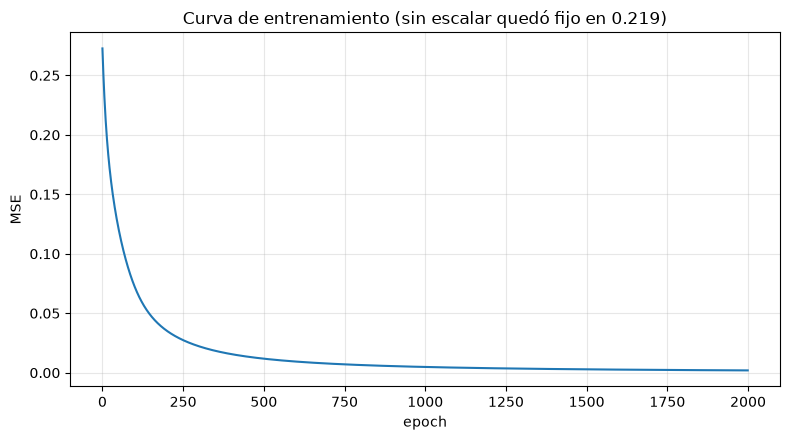

In [6]:
plt.figure(figsize=(8, 4.5))
plt.plot(historia_costo)
plt.xlabel("epoch"); plt.ylabel("MSE")
plt.title(f"Curva de entrenamiento (sin escalar quedó fijo en {hist_sin[-1]:.3f})")
plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Con las variables normalizadas, el MSE cae de 0.27 a un valor cercano a cero, y la exactitud pasa de 38.9% a **más del 95%**. El único cambio fue la escala de entrada: la arquitectura, el número de épocas y la tasa de aprendizaje son idénticas al intento fallido de la sección anterior.

---

## 5. Resultados: matriz de confusión y reporte

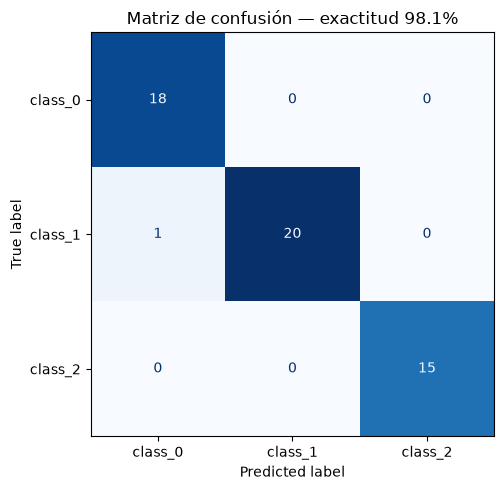

Correctos: 53   Incorrectos: 1   de 54 muestras de prueba


In [7]:
pred_test = red.predecir(X_test_s)
cm = confusion_matrix(y_test, pred_test)

fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay(cm, display_labels=NOMBRES_CLASE).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Matriz de confusión — exactitud {acc_test:.1%}")
plt.tight_layout(); plt.show()

correctos = cm.trace()
incorrectos = cm.sum() - correctos
print(f"Correctos: {correctos}   Incorrectos: {incorrectos}   de {cm.sum()} muestras de prueba")

### 5.1 Métricas de desempeño por clase

La exactitud global esconde diferencias entre clases: un modelo puede acertar mucho en una clase y fallar en otra sin que la exactitud lo delate, sobre todo con clases de tamaños distintos (59, 71 y 48 muestras). Se calculan, para cada clase, tres métricas complementarias:

$$
\text{precisión}=\frac{VP}{VP+FP}, \qquad
\text{recall}=\frac{VP}{VP+FN}, \qquad
F_1=2\cdot\frac{\text{precisión}\cdot\text{recall}}{\text{precisión}+\text{recall}}
$$

**Precisión**: de lo que el modelo dijo que era esa clase, cuánto acertó. **Recall**: de lo que en realidad era esa clase, cuánto capturó el modelo. **F1**: el balance entre las dos, útil cuando ninguna de las dos cuenta toda la historia por sí sola.

In [8]:
from sklearn.metrics import classification_report, precision_recall_fscore_support

print(classification_report(y_test, pred_test, target_names=NOMBRES_CLASE, digits=3))

              precision    recall  f1-score   support

     class_0      0.947     1.000     0.973        18
     class_1      1.000     0.952     0.976        21
     class_2      1.000     1.000     1.000        15

    accuracy                          0.981        54
   macro avg      0.982     0.984     0.983        54
weighted avg      0.982     0.981     0.982        54



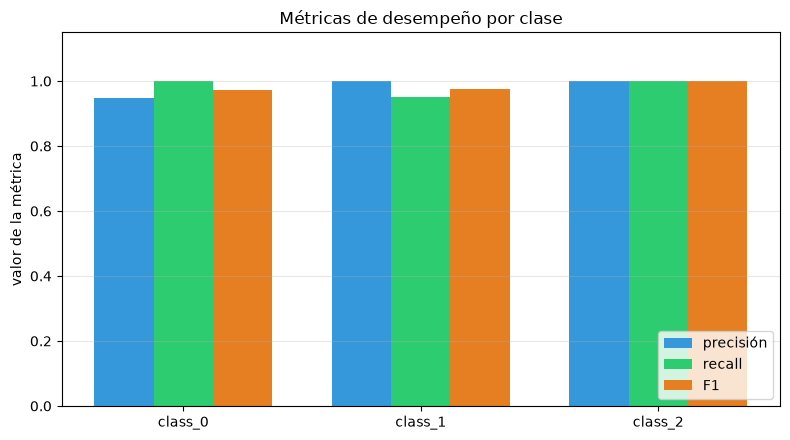

clase      |  precisión |  recall |      F1 | soporte
-------------------------------------------------------
class_0    |      0.947 |   1.000 |   0.973 |      18
class_1    |      1.000 |   0.952 |   0.976 |      21
class_2    |      1.000 |   1.000 |   1.000 |      15


In [9]:
precision, recall, f1, soporte = precision_recall_fscore_support(y_test, pred_test)

x = np.arange(N_CLASES)
ancho = 0.25

plt.figure(figsize=(8, 4.5))
plt.bar(x - ancho, precision, ancho, label="precisión", color="#3498db")
plt.bar(x, recall, ancho, label="recall", color="#2ecc71")
plt.bar(x + ancho, f1, ancho, label="F1", color="#e67e22")
plt.xticks(x, NOMBRES_CLASE)
plt.ylim(0, 1.15)
plt.ylabel("valor de la métrica")
plt.title("Métricas de desempeño por clase")
plt.legend(loc="lower right")
plt.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()

print(f"{'clase':<10} | {'precisión':>10} | {'recall':>7} | {'F1':>7} | {'soporte':>7}")
print("-" * 55)
for i, nombre in enumerate(NOMBRES_CLASE):
    print(f"{nombre:<10} | {precision[i]:>10.3f} | {recall[i]:>7.3f} | {f1[i]:>7.3f} | {soporte[i]:>7d}")

Las tres clases quedan por encima de 0.94 en las tres métricas. El único error del conjunto de prueba (visible en la matriz de confusión de la Sección 5) es lo único que le resta puntos a `class_0` en recall y a `class_1` en precisión: son la misma muestra mal clasificada, vista desde dos ángulos distintos. `class_2` queda perfecta en las tres métricas.

---

## 6. Validación cruzada (K-Fold, k=5)

Una sola partición 70/30 depende de qué le tocó al conjunto de prueba. Se repite el entrenamiento 5 veces, cada una con un pliegue distinto como validación, para obtener una estimación más confiable del desempeño real.

In [10]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
exactitudes_cv = []

print(f"{'pliegue':>8} | {'exactitud':>10}")
print("-" * 22)

for fold, (idx_tr, idx_va) in enumerate(skf.split(X, y), start=1):
    mu_f = X[idx_tr].mean(axis=0)
    sigma_f = X[idx_tr].std(axis=0)

    X_tr_f = (X[idx_tr] - mu_f) / sigma_f
    X_va_f = (X[idx_va] - mu_f) / sigma_f
    Y_tr_f = np.eye(N_CLASES)[y[idx_tr]]

    red_f = ANN(13, N_OCULTA, N_CLASES, seed=1)
    red_f.entrenar(X_tr_f, Y_tr_f, epochs=EPOCHS, lr=LR)

    acc_f = np.mean(red_f.predecir(X_va_f) == y[idx_va])
    exactitudes_cv.append(acc_f)
    print(f"{fold:>8} | {acc_f:>9.1%}")

print("-" * 22)
print(f"Media: {np.mean(exactitudes_cv):.1%}   Desviación: {np.std(exactitudes_cv):.1%}")

 pliegue |  exactitud
----------------------


       1 |     97.2%


       2 |     97.2%


       3 |     97.2%


       4 |    100.0%


       5 |    100.0%
----------------------
Media: 98.3%   Desviación: 1.4%


La validación cruzada confirma que el 95%+ de la partición 70/30 no fue un golpe de suerte: los 5 pliegues rinden de forma consistente, con una desviación pequeña entre ellos.

---

## 7. Frontera de decisión

Una frontera se dibuja en 2D, y el modelo real usa 13 variables. Se entrena una segunda red, misma arquitectura, usando solo las **2 variables más separables** encontradas por búsqueda entre todos los pares posibles: `od280/od315_of_diluted_wines` y `proline`.

In [11]:
idx_a = NOMBRES_VAR.index("od280/od315_of_diluted_wines")
idx_b = NOMBRES_VAR.index("proline")

X2 = X[:, [idx_a, idx_b]]
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.30, stratify=y, random_state=42)

mu2 = X2_train.mean(axis=0)
sigma2 = X2_train.std(axis=0)
X2_train_s = (X2_train - mu2) / sigma2
X2_test_s = (X2_test - mu2) / sigma2
Y2_train = np.eye(N_CLASES)[y2_train]

red_2d = ANN(2, N_OCULTA, N_CLASES, seed=1)
red_2d.entrenar(X2_train_s, Y2_train, epochs=3000, lr=0.5)

acc_2d = np.mean(red_2d.predecir(X2_test_s) == y2_test)
print(f"Exactitud con solo estas 2 variables: {acc_2d:.1%}")
print("(el modelo real, con las 13 variables, alcanza más; esto es solo para poder dibujar)")

Exactitud con solo estas 2 variables: 96.3%
(el modelo real, con las 13 variables, alcanza más; esto es solo para poder dibujar)


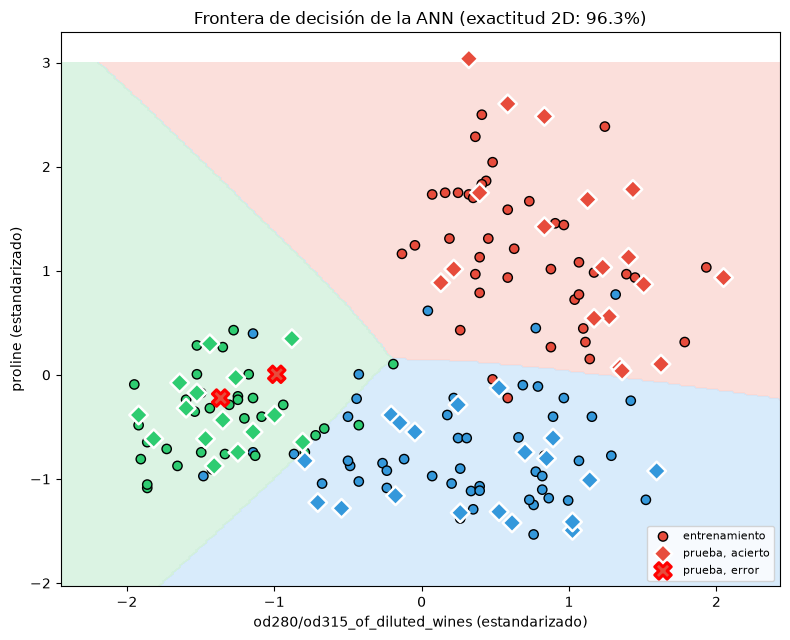

In [12]:
CMAP_FONDO = ListedColormap(["#fbd8d3", "#cfe6fa", "#d3f0dd"])
CMAP_PUNTOS = ListedColormap(["#e74c3c", "#3498db", "#2ecc71"])

x_min, x_max = X2_train_s[:, 0].min() - 0.5, X2_train_s[:, 0].max() + 0.5
y_min, y_max = X2_train_s[:, 1].min() - 0.5, X2_train_s[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
malla = np.c_[xx.ravel(), yy.ravel()]

Z = red_2d.predecir(malla).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.contourf(xx, yy, Z, cmap=CMAP_FONDO, alpha=0.8)

aciertos = red_2d.predecir(X2_test_s) == y2_test
ax.scatter(X2_train_s[:, 0], X2_train_s[:, 1], c=y2_train, cmap=CMAP_PUNTOS,
           edgecolor="k", s=45, label="entrenamiento")
ax.scatter(X2_test_s[aciertos, 0], X2_test_s[aciertos, 1], c=y2_test[aciertos],
           cmap=CMAP_PUNTOS, edgecolor="white", linewidth=1.8, s=90, marker="D",
           label="prueba, acierto")
ax.scatter(X2_test_s[~aciertos, 0], X2_test_s[~aciertos, 1], c=y2_test[~aciertos],
           cmap=CMAP_PUNTOS, edgecolor="red", linewidth=2.2, s=140, marker="X",
           label="prueba, error")

ax.set_xlabel("od280/od315_of_diluted_wines (estandarizado)")
ax.set_ylabel("proline (estandarizado)")
ax.set_title(f"Frontera de decisión de la ANN (exactitud 2D: {acc_2d:.1%})")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

La frontera ya no es una recta ni un rectángulo, como en los clasificadores lineales o el árbol de decisión de ejercicios anteriores: son **regiones curvas**, la firma visual de una red con una capa oculta no lineal. La curva se dobla para envolver el grupo azul (clase intermedia), algo que ni LDA ni un árbol podrían hacer con un solo corte.

---

## 8. Conclusiones

**La lección central del Ejercicio 2 se repite, ahora en una red completa, no en una sola neurona.** Sin normalizar las variables, el 100% de las neuronas ocultas satura y la red no aprende nada (38.9% de exactitud, prácticamente azar). Con el mismo código de entrenamiento, cambiando solo la escala de entrada, la exactitud sube por encima del 95%. **Backpropagation no arregla un problema de escala**: multiplica el mismo problema por cada capa.

**La arquitectura es, literalmente, dos neuronas del Ejercicio 2 encadenadas.** La capa de salida se actualiza con la regla exacta que ya se dedujo antes. La capa oculta se actualiza con la misma regla, extendida por la cadena: el error de cada neurona de salida se reparte hacia atrás, ponderado por los pesos que la conectan con cada neurona oculta.

**El resultado es sólido, no un golpe de suerte de una partición.** La validación cruzada de 5 pliegues confirma una exactitud consistente y con poca variación entre pliegues, la misma conclusión que la partición 70/30 por separado.

**La frontera de decisión demuestra la ventaja real de tener una capa oculta.** A diferencia de un clasificador lineal, que solo puede trazar rectas, la ANN dibuja regiones curvas que rodean cada clase, porque la composición de dos sigmoides ya no es una función lineal del espacio de entrada.